<div style="background-color: #2E7D32; color: #FFFFFF; padding: 25px; border-radius: 10px; text-align: center;">
    <span style="color: #FFFFFF; font-size: 36px; font-weight: bold;"><b>EDA Analysis</b></span>
</div>

In [1]:
print("hello")

hello


In [2]:
import pandas as pd 
import numpy as np
import matplotlib.pyplot as plt 
import seaborn as sns


In [13]:
customers = pd.read_csv(r"D:\Internship_project\Project_work\cleaned_output\Customers_Clean.csv")
delivery = pd.read_csv(r"D:\Internship_project\Project_work\cleaned_output\Delivery_Clean.csv")
feedback = pd.read_csv(r"D:\Internship_project\Project_work\cleaned_output\Feedback_Clean.csv")
menu_items = pd.read_csv(r"D:\Internship_project\Project_work\cleaned_output\Menu_Items_Clean.csv")
order_items = pd.read_csv(r"D:\Internship_project\Project_work\cleaned_output\Order_Items_Clean.csv")
orders = pd.read_csv(r"D:\Internship_project\Project_work\cleaned_output\Orders_Clean.csv")
outlets = pd.read_csv(r"D:\Internship_project\Project_work\cleaned_output\Outlets_Clean.csv")
promotions = pd.read_csv(r"D:\Internship_project\Project_work\cleaned_output\Promotions_Clean.csv")

## Compare Sales performance by Order Type

Order Volume:
 order_type
Delivery    54455
Dine-In     13514
Takeaway    11843
Name: order_id, dtype: int64

Total Revenue:
 order_type
Delivery    47294928
Dine-In     11703403
Takeaway    10316752
Name: total_amount, dtype: int64

Average Order Value (AOV):
 order_type
Delivery    868.513966
Dine-In     866.020645
Takeaway    871.126573
Name: total_amount, dtype: float64

Percentage Contribution (%):
 order_type
Delivery    68.231799
Dine-In     16.884353
Takeaway    14.883849
Name: total_amount, dtype: float64


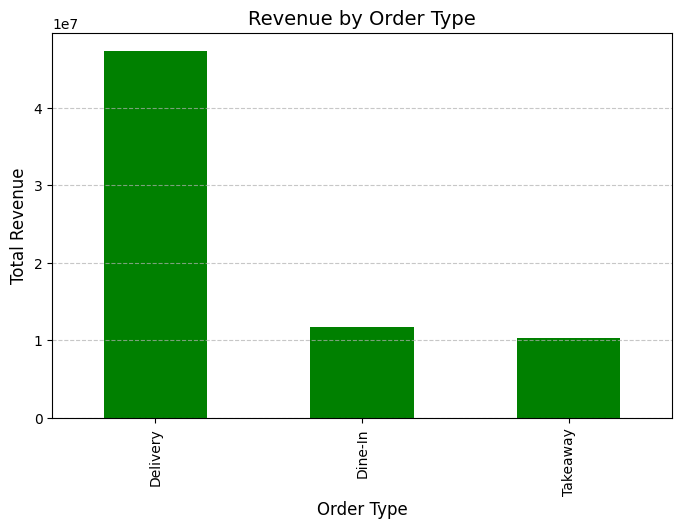

In [19]:
# 1. Order Volume (Count of orders)
order_volume = orders.groupby('order_type')['order_id'].count()
print("Order Volume:\n", order_volume)

# 2. Total Revenue
revenue = orders.groupby('order_type')['total_amount'].sum()
print("\nTotal Revenue:\n", revenue)

# 3. Average Order Value (AOV)
aov = orders.groupby('order_type')['total_amount'].mean()
print("\nAverage Order Value (AOV):\n", aov)

# 4. Percentage Contribution to Total Revenue
total_rev_all = revenue.sum()
revenue_percentage = (revenue / total_rev_all) * 100
print("\nPercentage Contribution (%):\n", revenue_percentage)

# 5. Simple Bar Chart for Revenue Comparison
revenue.plot(kind='bar', color='green', figsize=(8, 5))
plt.title('Revenue by Order Type', fontsize=14)
plt.xlabel('Order Type', fontsize=12)
plt.ylabel('Total Revenue', fontsize=12)
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()

__1. Compare Sales performance by Order Type__  

    Order Volume: Delivery is the clear leader with 54,455 orders, followed by Dine-In (13,514) and Takeaway (11,843).

    Total Revenue: Delivery generated the highest revenue at ~47.29M, compared to Dine-In (~11.70M) and Takeaway (~10.32M).

    Average Order Value (AOV): AOV is remarkably consistent across all three types, hovering closely between ~866 and ~871 per order (Delivery: ~868.51, Dine-In: ~866.02, Takeaway: ~871.13).

    Revenue Contribution: Delivery is the primary revenue driver, contributing 68.23% of total sales, while Dine-In (16.88%) and Takeaway (14.88%) split the remaining share relatively evenly.

## KPI: Returning Customer Rate

Total Customers: 15250
Repeat Customers (>1 order): 10439
Returning Customer Rate: 68.45%


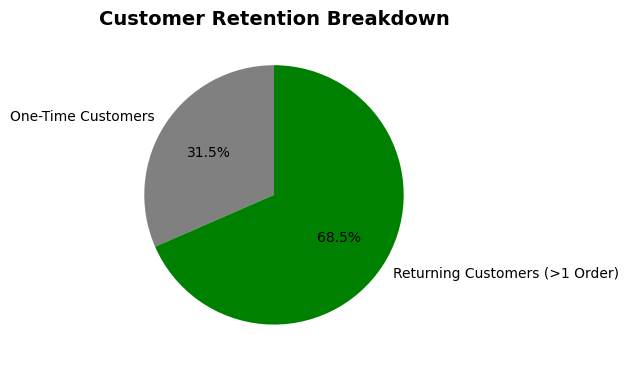

In [23]:
order_counts = orders.groupby('customer_id')['order_id'].count().reset_index()
order_counts.columns = ['customer_id', 'order_count']

total_customers = customers['customer_id'].nunique()
repeat_customers = (order_counts['order_count'] > 1).sum()

returning_customer_rate = (repeat_customers / total_customers) * 100

print(f"Total Customers: {total_customers}")
print(f"Repeat Customers (>1 order): {repeat_customers}")
print(f"Returning Customer Rate: {returning_customer_rate:.2f}%")


labels = ['One-Time Customers', 'Returning Customers (>1 Order)']
counts = [15250 - 10439, 10439]

plt.figure(figsize=(6, 6))
plt.pie(counts, labels=labels, autopct='%1.1f%%', colors=['gray', 'green'], startangle=90)

plt.title('Customer Retention Breakdown', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

__KPI: Returning Customer Rate__

Total Customers: 15,250 unique customers recorded in the database.

Repeat Customers: 10,439 customers have placed more than one order.

Returning Customer Rate: 68.45%, indicating high customer loyalty and strong repeat business.

   outlet_id  total_revenue  order_volume         aov
9     OUT010        1512635          1690  895.050296
22    OUT023        1494291          1681  888.929804
43    OUT044        1482375          1687  878.704801
4     OUT005        1468066          1613  910.146311
12    OUT013        1458840          1616  902.747525
46    OUT047        1453099          1667  871.685063
23    OUT024        1433184          1595  898.547962
5     OUT006        1433175          1652  867.539346
21    OUT022        1430021          1668  857.326739
40    OUT041        1425662          1611  884.954687


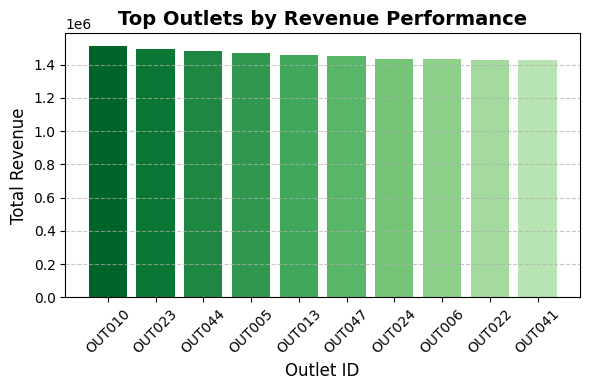

In [31]:
merged_df = pd.merge(orders, outlets, on='outlet_id', how='inner')

outlet_performance = merged_df.groupby('outlet_id').agg(
    total_revenue=('total_amount', 'sum'),
    order_volume=('order_id', 'count'),
    aov=('total_amount', 'mean')
).reset_index()

outlet_performance = outlet_performance.sort_values(by='total_revenue', ascending=False).head(10)

print(outlet_performance)

# Generate color gradient: darker for high revenue, lighter for low revenue
colors = plt.cm.Greens(np.linspace(0.9, 0.3, len(outlet_performance)))

plt.figure(figsize=(6, 4))
plt.bar(outlet_performance['outlet_id'], outlet_performance['total_revenue'], color=colors)

plt.title('Top Outlets by Revenue Performance', fontsize=14, fontweight='bold')
plt.xlabel('Outlet ID', fontsize=12)
plt.ylabel('Total Revenue', fontsize=12)
plt.xticks(rotation=45)
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

__KPI: Outlet Revenue Performance__  
    
    Top Performer: OUT010 leads all outlets with the highest revenue (~₹15.12L) and order volume (1,690 orders).

    Revenue Distribution: Performance among the top outlets is tightly clustered, with total revenue closely ranging between ₹14.25L and ₹15.12L.

    Order Volume & AOV: Order counts remain steady (1,595 to 1,690 orders), and Average Order Value (AOV) stays consistent between ~₹857 and ~₹910 across top branches.

## KPI: Customer Satisfaction Score

Average Food Rating: 3.75
Average Service Rating: 3.78
Average Ambience Rating: 3.75


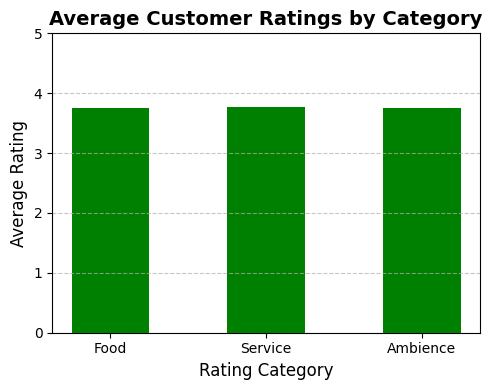

In [36]:
merged_df = pd.merge(feedback, delivery, on='order_id', how='inner')

avg_food = feedback['food_rating'].mean() if 'food_rating' in feedback.columns else 0
avg_service = feedback['service_rating'].mean() if 'service_rating' in feedback.columns else 0
avg_ambience = feedback['ambience_rating'].mean() if 'ambience_rating' in feedback.columns else 0

print(f"Average Food Rating: {avg_food:.2f}")
print(f"Average Service Rating: {avg_service:.2f}")
print(f"Average Ambience Rating: {avg_ambience:.2f}")

ratings = {
    'Food': avg_food,
    'Service': avg_service,
    'Ambience': avg_ambience,
}

plt.figure(figsize=(5, 4))
plt.bar(ratings.keys(), ratings.values(), color='green', width=0.5)
plt.title('Average Customer Ratings by Category', fontsize=14, fontweight='bold')
plt.xlabel('Rating Category', fontsize=12)
plt.ylabel('Average Rating', fontsize=12)
plt.ylim(0, 5)
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

__KPI: Customer Satisfaction Score__
 
    Average Ratings: Food (~3.75), Service (~3.78), and Ambience (~3.75) are extremely consistent across all reviews.

    Overall Experience: Customer feedback shows a steady performance hovering around the 3.75 to 3.78 mark out of 5, reflecting stable quality across categories.